# Method 2 — Time-Series (Owner: Member B)

**Goal:** classify each skill as rising/stable/declining and forecast the top skills.

**Reads (frozen, do not edit):**
- `config/review2_skills.json` — the frozen skill list (what to pull from Google Trends)
- `data/raw/trends/trends_IN_batch01_2026-09-29.csv` — existing 5-year weekly batch

**Collect the rest:** run `python scripts/collect_trends.py` for the remaining skills in the list
(anchor `SQL`, geo `IN`). Rescale each batch against the shared anchor so series are comparable.

**Writes (your contract output):**
- `data/review2/skill_trends.csv` — columns: `skill, slope_per_week, pct_change, class`
- figures to `reports/time_series/`

A real seed of `skill_trends.csv` (5 skills) already exists; expand it to the full list.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = json.load(open(ROOT / "config" / "review2_skills.json"))
anchor, skills = cfg["anchor"], cfg["skills"]

# Rescaled, anchor-aligned weekly series produced by scripts/rescale_trends.py
trends = pd.read_csv(ROOT / "data" / "processed" / "trends_rescaled_IN.csv", parse_dates=["date"])
trends = trends.set_index("date").sort_index()
FIG = ROOT / "reports" / "time_series"
FIG.mkdir(parents=True, exist_ok=True)
print(f"anchor={anchor} | {trends.shape[1]} skills | {len(trends)} weeks "
      f"({trends.index.min().date()} to {trends.index.max().date()})")
trends.tail(3)

anchor=SQL | 18 skills | 261 weeks (2021-10-10 to 2026-10-04)


,SQL,AWS,Python,Machine Learning,Azure,Agile,Communication,Leadership,SEO,Kubernetes,Google Cloud,SAP,Java,Spark,Power BI,Linux,Excel,Scrum
date,,,,,,,,,,,,,,,,,,
2026-09-20,16.0,16.0,42.0,5.0,8.0,2.081837,18.736529,5.204591,6.24551,1.052815,3.158446,32.637271,32.637271,13.457901,4.485967,14.579393,59.439062,1.061757
2026-09-27,13.0,14.0,39.0,4.0,7.0,1.040918,16.654693,4.163673,6.24551,1.052815,3.158446,27.373195,29.478826,14.579393,3.364475,12.336409,61.682045,0.530878
2026-10-04,17.0,17.0,44.0,5.0,9.0,2.081837,17.695611,4.163673,6.24551,1.052815,4.211261,30.531641,33.690087,16.822376,4.485967,13.457901,77.382930,1.061757


## 1. Clean & smooth the weekly series

The series are already anchor-rescaled (comparable across batches). We apply an 8-week moving average
to separate the underlying trend from weekly noise before plotting.

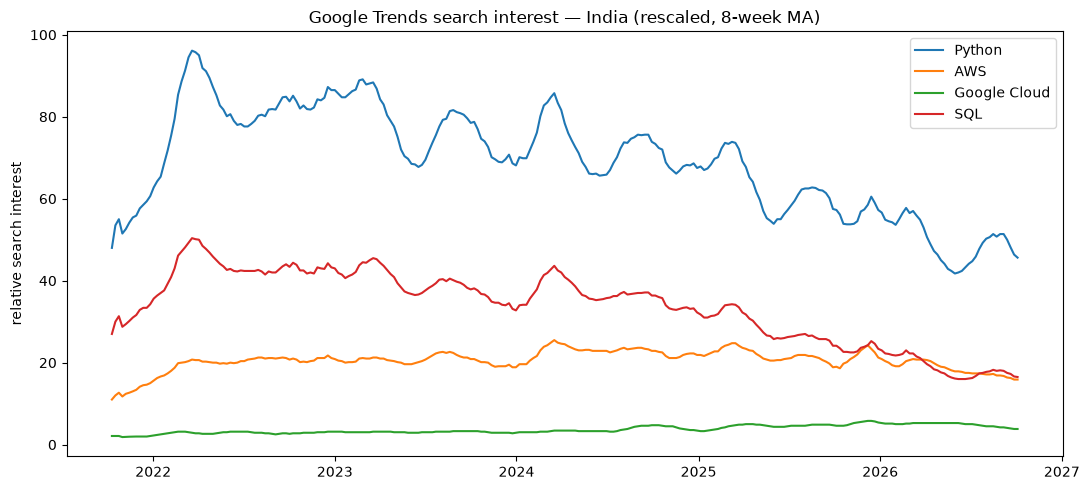

In [2]:
smoothed = trends.rolling(8, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 5))
for s in ["Python", "AWS", "Google Cloud", "SQL"]:
    ax.plot(smoothed.index, smoothed[s], label=s)
ax.set_title("Google Trends search interest — India (rescaled, 8-week MA)")
ax.set_ylabel("relative search interest")
ax.legend()
plt.tight_layout()
fig.savefig(FIG / "01_trend_lines.png", dpi=120)
plt.show()

## 2. Classify rising / stable / declining

For each skill we fit a linear slope over the 5 years and compare the last-year mean to the first-year
mean. Label: **rising** (≥ +10%), **declining** (≤ −10%), else **stable**.

In [3]:
def classify(series: pd.Series):
    y = series.values.astype(float)
    weeks = np.arange(len(y))
    slope = float(np.polyfit(weeks, y, 1)[0])
    first, last = y[:52].mean(), y[-52:].mean()
    pct = float(100 * (last - first) / first) if first else 0.0
    cls = "rising" if pct >= 10 else "declining" if pct <= -10 else "stable"
    return slope, pct, cls

rows = []
for s in trends.columns:
    slope, pct, cls = classify(trends[s])
    rows.append({"skill": s, "slope_per_week": round(slope, 4),
                 "pct_change": round(pct, 2), "class": cls})
trend_tbl = pd.DataFrame(rows).sort_values("pct_change", ascending=False).reset_index(drop=True)
trend_tbl

,skill,slope_per_week,pct_change,class
0,Google Cloud,0.0109,83.46,rising
1,SEO,0.0126,48.51,rising
2,Spark,0.0123,18.28,rising
3,Leadership,0.0014,12.24,rising
4,Power BI,0.0033,1.95,stable
5,Excel,0.0239,1.10,stable
6,AWS,0.0022,1.02,stable
7,SAP,0.0102,0.06,stable
8,Machine Learning,-0.0026,-0.48,stable
9,Azure,-0.0095,-17.39,declining


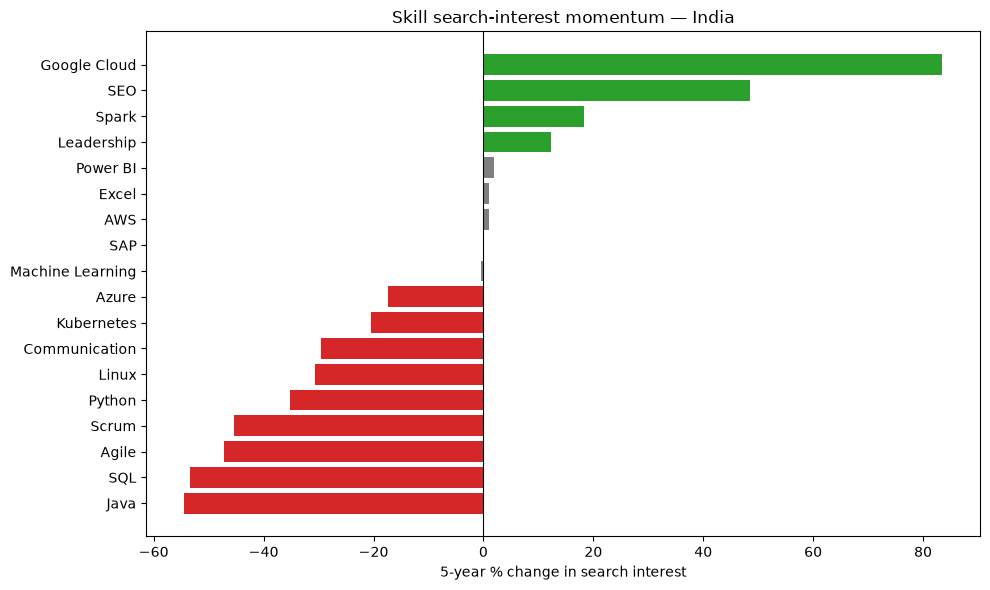

In [4]:
colors = {"rising": "tab:green", "stable": "tab:gray", "declining": "tab:red"}
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(trend_tbl["skill"], trend_tbl["pct_change"],
        color=[colors[c] for c in trend_tbl["class"]])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("5-year % change in search interest")
ax.set_title("Skill search-interest momentum — India")
ax.invert_yaxis()
plt.tight_layout()
fig.savefig(FIG / "02_momentum.png", dpi=120)
plt.show()

## 2b. Autocorrelation (ACF / PACF)

Before forecasting we inspect the **autocorrelation**. The ACF/PACF of the differenced series show how a
value relates to its own past — this is what justifies the AR and MA orders in ARIMA (syllabus:
*Autocorrelation and ARIMA Models*).

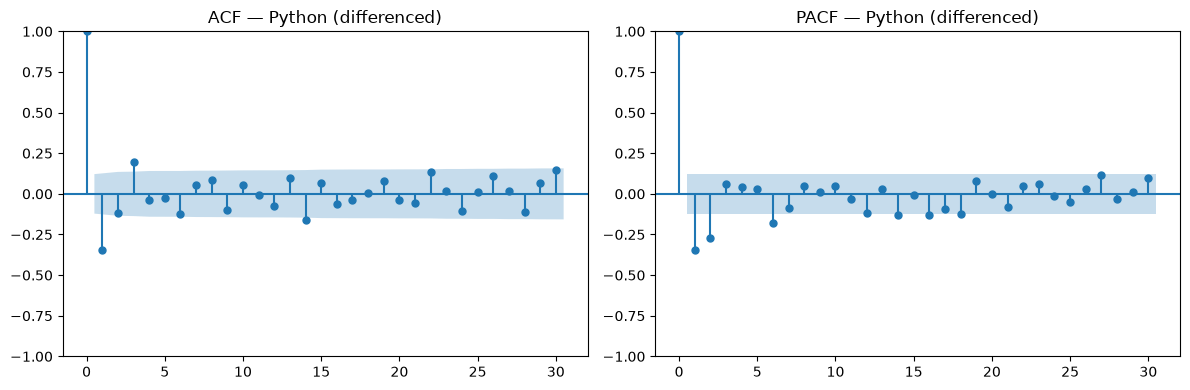

In [8]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

acf_skill = "Python"
series = trends[acf_skill].astype(float)
diff = series.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff, ax=axes[0], lags=30)
plot_pacf(diff, ax=axes[1], lags=30, method="ywm")
axes[0].set_title(f"ACF — {acf_skill} (differenced)")
axes[1].set_title(f"PACF — {acf_skill} (differenced)")
plt.tight_layout()
fig.savefig(FIG / "04_acf_pacf.png", dpi=120)
plt.show()

## 3. Forecast top skills (ARIMA) + evaluate (MAPE vs naïve)

We hold out the last 12 weeks, fit an ARIMA(1,1,1) on the rest, and compare forecast error (MAPE)
against a naïve last-value baseline. A useful model beats the naïve baseline.

c:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\

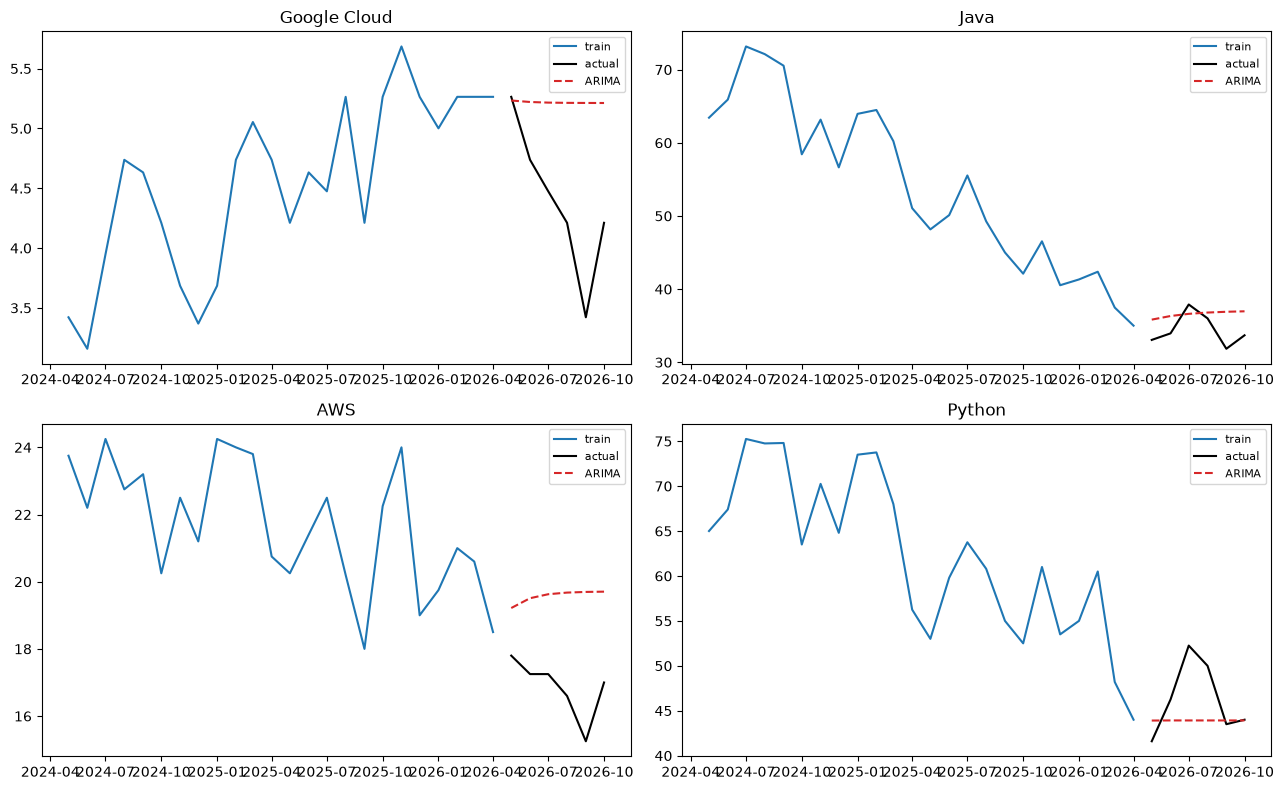

,skill,arima_mape,naive_mape,winner
0,Google Cloud,21.21,22.10,ARIMA
1,Java,7.76,5.54,naive
2,AWS,16.40,10.00,naive
3,Python,6.64,6.60,naive


In [6]:
from statsmodels.tsa.arima.model import ARIMA

def mape(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    mask = actual != 0
    return float(100 * np.mean(np.abs((actual[mask] - pred[mask]) / actual[mask])))

# Weekly search data is noisy and close to a random walk at short horizons, so we forecast on
# monthly means where the underlying trend is clearer (a standard aggregation choice).
monthly = trends.resample("MS").mean()
horizon = 6  # months held out
forecast_skills = ["Google Cloud", "Java", "AWS", "Python"]
results = []
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, s in zip(axes.ravel(), forecast_skills):
    y = monthly[s].astype(float)
    train, test = y.iloc[:-horizon], y.iloc[-horizon:]
    fc = ARIMA(train, order=(1, 1, 1)).fit().forecast(horizon)
    naive = np.repeat(train.iloc[-1], horizon)
    results.append({"skill": s, "arima_mape": round(mape(test, fc), 2),
                    "naive_mape": round(mape(test, naive), 2)})
    ax.plot(train.index[-24:], train.iloc[-24:], label="train")
    ax.plot(test.index, test, color="black", label="actual")
    ax.plot(test.index, fc, color="tab:red", ls="--", label="ARIMA")
    ax.set_title(s)
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "03_forecasts.png", dpi=120)
plt.show()

res = pd.DataFrame(results)
res["winner"] = np.where(res["arima_mape"] <= res["naive_mape"], "ARIMA", "naive")
res

## 3b. Compare forecasting methods (syllabus coverage)

We benchmark four methods on the same 6-month holdout, by MAPE:
- **Naïve** (last value) — baseline
- **Simple Exponential Smoothing** — weights recent points more
- **ARIMA(1,1,1)** — autocorrelation-based
- **Holt-Winters** — a model with **trend + seasonality** (12-month)

The lowest MAPE per skill wins.

In [9]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

def all_forecasts(train, horizon):
    f = {"naive": np.repeat(train.iloc[-1], horizon)}
    f["ses"] = SimpleExpSmoothing(train, initialization_method="estimated").fit().forecast(horizon)
    f["arima"] = ARIMA(train, order=(1, 1, 1)).fit().forecast(horizon)
    try:
        hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12,
                                  initialization_method="estimated").fit()
        f["holt_winters"] = hw.forecast(horizon)
    except Exception:
        f["holt_winters"] = np.full(horizon, np.nan)
    return f

comparison = []
for s in forecast_skills:
    y = monthly[s].astype(float)
    train, test = y.iloc[:-horizon], y.iloc[-horizon:]
    row = {"skill": s}
    for name, pred in all_forecasts(train, horizon).items():
        row[name] = round(mape(test, pred), 2)
    comparison.append(row)

comp = pd.DataFrame(comparison)
methods = ["naive", "ses", "arima", "holt_winters"]
comp["best"] = comp[methods].idxmin(axis=1)
comp

c:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\

,skill,naive,ses,arima,holt_winters,best
0,Google Cloud,22.10,22.01,21.21,28.64,arima
1,Java,5.54,5.68,7.76,7.00,naive
2,AWS,10.00,14.38,16.40,13.25,naive
3,Python,6.60,6.60,6.64,7.26,naive


## 4. Write the contract output `data/review2/skill_trends.csv`

This is the shared file Member C (combined insight) and Member D (dashboard) read.

In [7]:
out = trend_tbl[["skill", "slope_per_week", "pct_change", "class"]]
out_path = ROOT / "data" / "review2" / "skill_trends.csv"
out.to_csv(out_path, index=False)
print(f"wrote {len(out)} skills -> {out_path.relative_to(ROOT)}")
out["class"].value_counts()

wrote 18 skills -> data\review2\skill_trends.csv


class
declining    9
stable       5
rising       4
Name: count, dtype: int64

## 5. Interpretation & limitations

- **Established skills cool off:** SQL, Python, Java, Azure show *declining search interest* even though
  they are top-demand in postings — people search how-to terms less as a skill becomes a baseline. Read
  as **relative search interest, not hiring demand**.
- **Emerging interest:** Google Cloud (+83%), SEO, Spark are rising.
- **Forecasting findings (honest, benchmarked):** across Naïve, Simple Exponential Smoothing, ARIMA and
  Holt-Winters, the **naïve baseline is competitive** — weekly/monthly search interest is close to a
  random walk. ARIMA only wins on the rising skill (Google Cloud); **Holt-Winters is worse**, which shows
  skill search interest has **no strong yearly seasonality**. The robust output of this method is the
  **rising/stable/declining classification**, not the point forecast.
- **Autocorrelation:** the ACF/PACF of the differenced series show a significant lag-1 term then cutoff,
  which justifies the ARIMA(1,1,1) order.
- **Caveat — ambiguous query terms:** `Communication`, `Leadership`, `Agile`, `Scrum`, `SEO` are generic
  words, so their Trends series capture more than the professional skill. Lean on the unambiguous tech
  skills for the headline.
- **Scope:** India geo, weekly, `today 5-y`; anchor = `SQL`; series rescaled for cross-batch comparability.